<a href="https://colab.research.google.com/github/hwayalew/L03-tree-stability/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.

Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they?

4. Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Raffaella Alpaca, Helen Ayalew, Angel Pavu

**Date:** 11/13/2026

In [ ]:
# Your Phase 1 solution to the problem goes here.
import pandas as pd

# Check out the data set heart_failure and appropriately clean it.
df = pd.read_csv('heart_failure_clinical_records_dataset.csv')
df

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
294,62.0,0,61,1,38,1,155000.00,1.1,143,1,1,270,0
295,55.0,0,1820,0,38,0,270000.00,1.2,139,0,0,271,0
296,45.0,0,2060,1,60,0,742000.00,0.8,138,0,0,278,0
297,45.0,0,2413,0,38,0,140000.00,1.4,140,1,1,280,0


In [ ]:
print(df.shape)

(299, 13)


In [ ]:
print(df.dtypes)

age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object


In [ ]:
df.isna().sum()

,0
age,0
anaemia,0
creatinine_phosphokinase,0
diabetes,0
ejection_fraction,0
high_blood_pressure,0
platelets,0
serum_creatinine,0
serum_sodium,0
sex,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

# Perform a train-test split for a specific seed (save the seed for reproducibility).
X = df.drop('DEATH_EVENT', axis=1)
y = df['DEATH_EVENT']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
seeds = [42, 11, 100]

for seed in seeds:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)

    tree_model = DecisionTreeClassifier(random_state=seed)
    tree_model.fit(X_train, y_train)
    tree_predictions = tree_model.predict(X_test)

    linear_model = LinearRegression()
    linear_model.fit(X_train, y_train)
    linear_predictions = linear_model.predict(X_test)

    # Evaluate the performance of the models.
    tree_accuracy = accuracy_score(y_test, tree_predictions)
    linear_accuracy = accuracy_score(y_test, linear_predictions.round())

    tree_mse = mean_squared_error(y_test, tree_predictions)
    linear_mse = mean_squared_error(y_test, linear_predictions)

    tree_r2 = r2_score(y_test, tree_predictions)
    linear_r2 = r2_score(y_test, linear_predictions)

    print(f"Tree {seed}:")
    print("Tree Model Accuracy:", tree_accuracy)
    print("Linear Model Accuracy:", linear_accuracy)
    print("Tree Model Mean Squared Error:", tree_mse)
    print("Linear Model MSE:", linear_mse)
    print("Tree Model R^2 Score:", tree_r2)
    print("Linear Model R^2 Score:", linear_r2)
    print()

Tree 42:
Tree Model Accuracy: 0.6333333333333333
Linear Model Accuracy: 0.7833333333333333
Tree Model Mean Squared Error: 0.36666666666666664
Linear Model MSE: 0.17868807219099922
Tree Model R^2 Score: -0.5085714285714287
Linear Model R^2 Score: 0.2648262172713174

Tree 11:
Tree Model Accuracy: 0.8
Linear Model Accuracy: 0.8666666666666667
Tree Model Mean Squared Error: 0.2
Linear Model MSE: 0.1287458561238458
Tree Model R^2 Score: 0.015047879616962745
Linear Model R^2 Score: 0.36595748010144336

Tree 100:
Tree Model Accuracy: 0.7166666666666667
Linear Model Accuracy: 0.7833333333333333
Tree Model Mean Squared Error: 0.2833333333333333
Linear Model MSE: 0.17086120183799844
Tree Model R^2 Score: -0.24542124542124544
Linear Model R^2 Score: 0.2489617501626442



Question: How different are the trees that you get? Your linear model coefficients? Set aside the predictions these models make.

Answer: The values of the trees accuracy vary by 0.17 from tree 42 to tree 11 and by 0.09 from tree 11 to tree 100. The values of linear coefficients vary by 0.08 from tree 42 to tree 11 and -0.08 from tree 11 to tree 100.

4. Instead of focusing on the tree or model coefficients, do three things:

  a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?

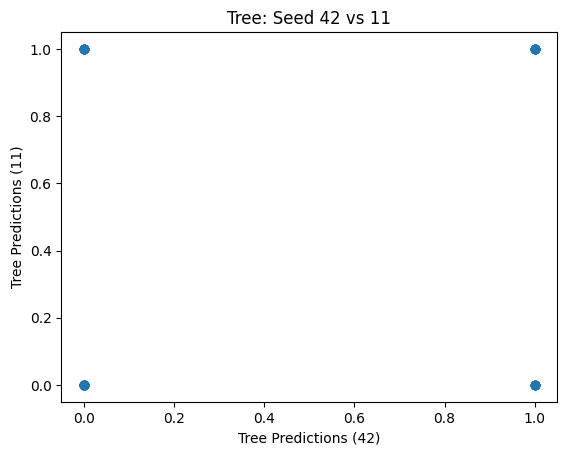

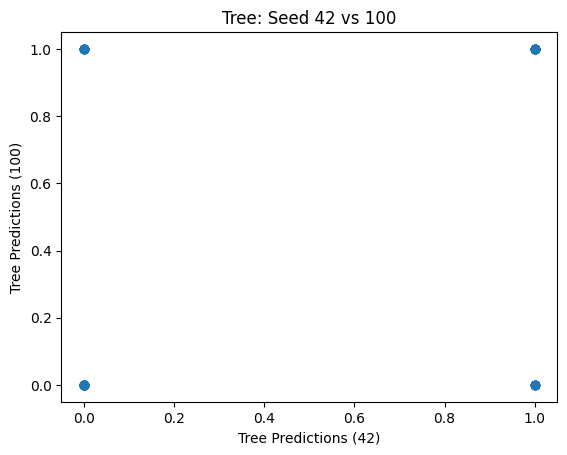

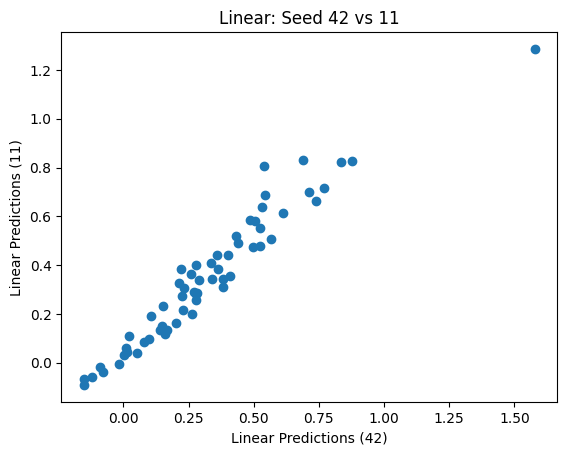

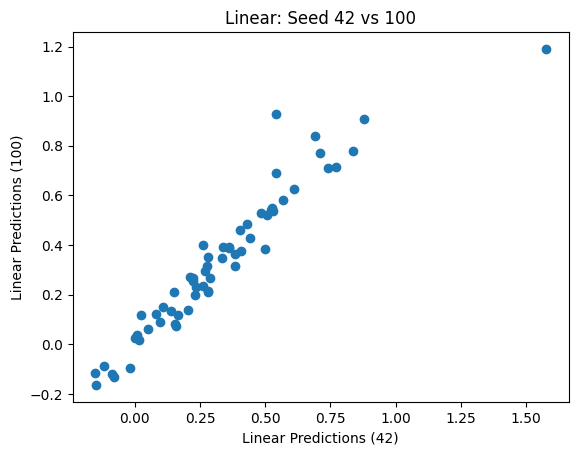

In [ ]:
#question 4(a)

#save predictions for each seed
tree_preds = {}
linear_preds = {}

#use the same test set to compare predictions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

for seed in [42, 11, 100]:
    X_train_seed, X_test_seed, y_train_seed, y_test_seed = train_test_split(
        X, y, test_size=0.2, random_state=seed
    )

    tree = DecisionTreeClassifier(random_state=seed)
    tree.fit(X_train_seed, y_train_seed)
    tree_preds[seed] = tree.predict(X_test)

    linear = LinearRegression()
    linear.fit(X_train_seed, y_train_seed)
    linear_preds[seed] = linear.predict(X_test)

#scatterplots for trees
for seed in [11, 100]:
    plt.scatter(tree_preds[42], tree_preds[seed])
    plt.xlabel("Tree Predictions (42)")
    plt.ylabel(f"Tree Predictions ({seed})")
    plt.title(f"Tree: Seed 42 vs {seed}")
    plt.show()

#scatterplots for linear models
for seed in [11, 100]:
    plt.scatter(linear_preds[42], linear_preds[seed])
    plt.xlabel("Linear Predictions (42)")
    plt.ylabel(f"Linear Predictions ({seed})")
    plt.title(f"Linear: Seed 42 vs {seed}")
    plt.show()

The scatterplots show that the linear regression predictions are fairly similar across the different random seeds. Most points follow an upward diagonal pattern, meaning that the models make similar predictions even when the training data changes. The decision tree plots only show four possible combinations because the predictions are either 0 or 1. Some predictions agree while others disagree, but we cant tell how often from these plots alone.

b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?

In [ ]:
#question 4(b)Correlation
import numpy as np
#correlation for decision trees
for seed in [11, 100]:
    correlation = np.corrcoef(tree_preds[42], tree_preds[seed])[0, 1]
    print(f"Tree correlation (42 vs {seed}): {correlation:.4f}")

#correlation for linear models
for seed in [11, 100]:
    correlation = np.corrcoef(linear_preds[42], linear_preds[seed])[0, 1]
    print(f"Linear correlation (42 vs {seed}): {correlation:.4f}")

Tree correlation (42 vs 11): 0.2968
Tree correlation (42 vs 100): 0.4486
Linear correlation (42 vs 11): 0.9653
Linear correlation (42 vs 100): 0.9535


The decision tree correlations were 0.2968 and 0.4486, showing weak to moderate relationships between predictions. The linear regression correlations were much higher, at 0.9653 and 0.9535, showing very strong relationships. This suggests that the linear regression models are more stable across different random seeds, while the decision trees are more sensitive to changes in the training data.

c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

In [ ]:
#question 4(c) - Simple Linear Regression

#decision Trees
for seed in [11, 100]:
    X_pred = tree_preds[42].reshape(-1, 1)
    y_pred = tree_preds[seed]

    model = LinearRegression()
    model.fit(X_pred, y_pred)

    print(f"Tree: 42 vs {seed}")
    print("Intercept:", model.intercept_)
    print("Slope:", model.coef_[0])
    print("R²:", model.score(X_pred, y_pred))
    print()

#linear Models
for seed in [11, 100]:
    X_pred = linear_preds[42].reshape(-1, 1)
    y_pred = linear_preds[seed]

    model = LinearRegression()
    model.fit(X_pred, y_pred)

    print(f"Linear: 42 vs {seed}")
    print("Intercept:", model.intercept_)
    print("Slope:", model.coef_[0])
    print("R²:", model.score(X_pred, y_pred))
    print()

Tree: 42 vs 11
Intercept: 0.3170731707317073
Slope: 0.31450577663671375
R²: 0.08806161745827978

Tree: 42 vs 100
Intercept: 0.21951219512195114
Slope: 0.46469833119383847
R²: 0.20122104771790617

Linear: 42 vs 11
Intercept: 0.06042001891266302
Slope: 0.895383387867469
R²: 0.931849432505111

Linear: 42 vs 100
Intercept: 0.029090633202160987
Slope: 0.934177690578886
R²: 0.9090878414573945



The decision tree models had intercepts of 0.3171 and 0.2195, slopes of 0.3145 and 0.4647, and low R² values of 0.0881 and 0.2012. This shows that their predictions changed quite a bit across different random seeds.

The linear regression models had intercepts closer to 0 (0.0604 and 0.0291), slopes closer to 1 (0.8954 and 0.9342), and high R² values (0.9318 and 0.9091). This means their predictions were more consistent across different training splits.

Overall, linear regression was more stable than the decision trees in this experiment.

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?

The linear models appear to have relatively similar coefficients and predictions across different train/test splits. Their predictions had high correlations, showing that they are fairly stable even when the training data changes. On the other hand, decision trees showed more variation across the splits, with much lower correlations between predictions. This suggests that linear models are more stable than decision trees for this dataset.

**Question 6: True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."**

For this dataset the statement is **false** for the trees since models that look different from split to split do not necessarily make similar predictions. The seed-42 decision tree’s predictions had correlations of only 0.30 and 0.45 with those of the trees trained on the other splits. When we regressed one tree’s predictions on another’s, the slopes were far from 1 (0.31 and 0.46), the intercepts were far from 0 (0.32 and 0.22), and the R² values were low (0.09 and 0.20). So the trees changed in both structure and predictions. The linear models, by contrast, had highly similar predictions, with correlations of 0.965 and 0.954, slopes near 0.9, intercepts near 0, and R² around 0.91 to 0.93. They also had similar coefficients across splits, so they don’t show that very different-looking models give similar predictions. They are simply stable models. The comparison is somewhat harsher on the trees because a DecisionTreeClassifier outputs hard 0/1 labels, which limits how much its predictions can correlate. On this small dataset (299 rows), the claim holds for the linear models but not for the trees.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** b0b0d41c60f034f1e4288f8f1c97c98826772e5b
- **AI tool and model used:** Claude Sonnet

### *Prompts used

1. Here is my team’s DS 3001 Tree Stability notebook and the assignment rubric. Review my Phase 1 solution against the rubric question by question (Q1–Q6) and tell me what is incorrect, missing, or could be optimized.
2. Based on that review, give me only the most necessary changes as a list.

### *AI-proposed changes


1. Add real cleaning checks in Q1: duplicate rows, 0/1 validation of the binary columns, value ranges and outcome balance, plus a short justification. Keep the outliers and the time column, and document why.
2. Use 5 seeds (42 plus four more) stored as constants, and keep every split, model and prediction in dictionaries. Add stratify=y so each split keeps the same share of deaths.
3. Limit the tree to max_depth=4, min_samples_leaf=5 and use predict_proba instead of hard 0/1 labels. Evaluate both models with accuracy, AUC and MSE.
4. Compare the actual tree structure (root split, depth, number of leaves, top features) and the standardized linear coefficients with their spread across seeds. Phase 1 reported accuracy differences as if they were coefficients, and 4.1 was unanswered.
5. Put all the scatterplots in one grid with a y = x reference line. Report correlation, intercept, slope and R² for all four alternative seeds in one table.
6. Revise the Q6 answer. With probability outputs and a depth-limited tree, the trees' predictions across seeds are fairly similar (average correlation about 0.84), so the answer changes from "false" to "true, with a caveat."

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept (modify) | Phase 1 only printed the shape, dtypes and missing values, which does not show the data was cleaned. We accepted the added checks for duplicates, 0/1 values in the binary columns, value ranges and outcome balance.|
| 2 | Accept | Phase 1 used only 3 seeds (2 additional) and its loop overwrote everything except the last split. Using 5 seeds saved as constants earns the full credit for additional seeds, and storing splits, models and predictions in dictionaries means the Q2 predictions are actually set aside.|
| 3 | Modify | Phase 1 used an unpruned tree that outputs only 0/1, which limits how correlated its predictions can be and makes it look less stable. We accepted using `predict_proba` and a depth-limited tree (`max_depth=4, min_samples_leaf=5`) with accuracy, AUC and MSE for both models.|
| 4 | Accept | Phase 1 reported accuracy differences and called them coefficient differences, and the question about coefficients varying by different amounts was unanswered. We accepted comparing the real tree structure (root split, depth, leaves, top features) and the standardized linear coefficients with their spread and sign consistency across seeds. |
| 5 | Accept | The reference line makes it clear whether predictions are similar, and one table with correlation, intercept, slope and R² for all four alternative seeds covers parts 4b and 4c. |
| 6 | Accept | Running the revised code on the real data showed that Phase 1's answer to Q6 ("false") depended on using a fully grown tree with hard 0/1 labels. With probability outputs and a depth-limited tree, the trees' predictions across five seeds had an average correlation of about 0.84, compared with about 0.44 for the unpruned 0/1 trees, so we revised Q6 to "true, with a caveat."|

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [1]:
# Your Phase 2 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, mean_squared_error, roc_auc_score

#Q1

df = pd.read_csv('heart_failure_clinical_records_dataset.csv')
print('Shape:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))

binary_cols = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking', 'DEATH_EVENT']
for c in binary_cols:
    assert set(df[c].unique()) <= {0, 1}, f'{c} is not 0/1'

print(df.describe().T[['min', 'mean', 'max']], '\n')
print('Outcome balance:\n', df['DEATH_EVENT'].value_counts(normalize=True).round(3))

X = df.drop(columns='DEATH_EVENT')
y = df['DEATH_EVENT']

Shape: (299, 13)
Missing values: 0
Duplicate rows: 0
                              min           mean       max
age                          40.0      60.833893      95.0
anaemia                       0.0       0.431438       1.0
creatinine_phosphokinase     23.0     581.839465    7861.0
diabetes                      0.0       0.418060       1.0
ejection_fraction            14.0      38.083612      80.0
high_blood_pressure           0.0       0.351171       1.0
platelets                 25100.0  263358.029264  850000.0
serum_creatinine              0.5       1.393880       9.4
serum_sodium                113.0     136.625418     148.0
sex                           0.0       0.648829       1.0
smoking                       0.0       0.321070       1.0
time                          4.0     130.260870     285.0
DEATH_EVENT                   0.0       0.321070       1.0 

Outcome balance:
 DEATH_EVENT
0    0.679
1    0.321
Name: proportion, dtype: float64


The data has 299 patients, 12 predictors and a binary outcome (DEATH_EVENT, about 32% = 1). There are no missing values or duplicate rows, and every binary column contains only 0/1, so no rows needed removing or imputing. creatinine_phosphokinase, platelets and serum_creatinine have extreme values, but they are clinically plausible, so we kept them. time is the follow-up period and would not be known at admission, but we kept it because the goal is model stability, not deployment.

In [2]:
#Q2 and Q3

SEEDS = [42, 11, 100, 7, 2024]   # 42 = the Q2 model; the other four are the Q3 repeats
BASE = 42
TREE_PARAMS = dict(max_depth=4, min_samples_leaf=5)   # same settings for every seed

splits, trees, lins, rows = {}, {}, {}, []
for s in SEEDS:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=s, stratify=y)
    splits[s] = (X_tr, X_te, y_tr, y_te)
    trees[s] = DecisionTreeClassifier(random_state=s, **TREE_PARAMS).fit(X_tr, y_tr)
    lins[s] = LinearRegression().fit(X_tr, y_tr)

    p_tree = trees[s].predict_proba(X_te)[:, 1]
    p_lin = lins[s].predict(X_te)
    rows.append({
        'seed': s,
        'tree_acc': accuracy_score(y_te, p_tree >= 0.5),
        'lin_acc': accuracy_score(y_te, p_lin >= 0.5),
        'tree_auc': roc_auc_score(y_te, p_tree),
        'lin_auc': roc_auc_score(y_te, p_lin),
        'tree_mse': mean_squared_error(y_te, p_tree),
        'lin_mse': mean_squared_error(y_te, p_lin),
    })
print('Own-test-set performance by seed:\n', pd.DataFrame(rows).set_index('seed').round(3), '\n')

# How different do the trees look?
tree_summary = pd.DataFrame({
    s: {
        'root split': f"{X.columns[t.tree_.feature[0]]} <= {t.tree_.threshold[0]:.2f}",
        'depth': t.get_depth(),
        'leaves': t.get_n_leaves(),
        'top-3 features': ', '.join(pd.Series(t.feature_importances_, X.columns).nlargest(3).index),
    } for s, t in trees.items()
}).T
print(tree_summary.to_string(), '\n')

# How different are the linear coefficients? (standardized so features are comparable)
coefs = pd.DataFrame({s: pd.Series(m.coef_, X.columns) * splits[s][0].std() for s, m in lins.items()})
coefs['mean'] = coefs.mean(axis=1)
coefs['std'] = coefs[SEEDS].std(axis=1)
coefs['same_sign_all_seeds'] = (np.sign(coefs[SEEDS]).nunique(axis=1) == 1)
print('Standardized linear coefficients:\n', coefs.round(3).sort_values('std', ascending=False))

Own-test-set performance by seed:
       tree_acc  lin_acc  tree_auc  lin_auc  tree_mse  lin_mse
seed                                                         
42       0.817    0.817     0.787    0.854     0.158    0.148
11       0.833    0.867     0.883    0.937     0.151    0.115
100      0.783    0.833     0.843    0.840     0.151    0.155
7        0.800    0.867     0.873    0.917     0.147    0.138
2024     0.817    0.850     0.741    0.863     0.174    0.143 

         root split depth leaves                             top-3 features
42    time <= 73.50     4     13  time, serum_creatinine, ejection_fraction
11    time <= 73.50     4     14          time, serum_creatinine, platelets
100   time <= 67.50     4     13  time, serum_creatinine, ejection_fraction
7     time <= 67.50     4     12                time, serum_creatinine, age
2024  time <= 73.50     4     13       time, serum_creatinine, serum_sodium 

Standardized linear coefficients:
                              42     

Q3.2 and Q4.1 Explanation

The trees are built from a similar set of important variables, but they differ in exact thresholds, in which variables appear in lower branches, and in the number of leaves (see the table above). Each split depends on the few observations near a threshold, so a different training set can change a split and everything beneath it. Linear coefficients. The standardized coefficients of the strong predictors keep the same sign and similar size across all five seeds. The coefficients vary by different amounts: each is estimated on about 239 patients with similar noise, so strong predictors are large relative to their spread, while weak predictors (e.g., sex, smoking, anaemia) are near 0 with a spread as large as the coefficient, and their sign can flip (see the std and same_sign_all_seeds columns).

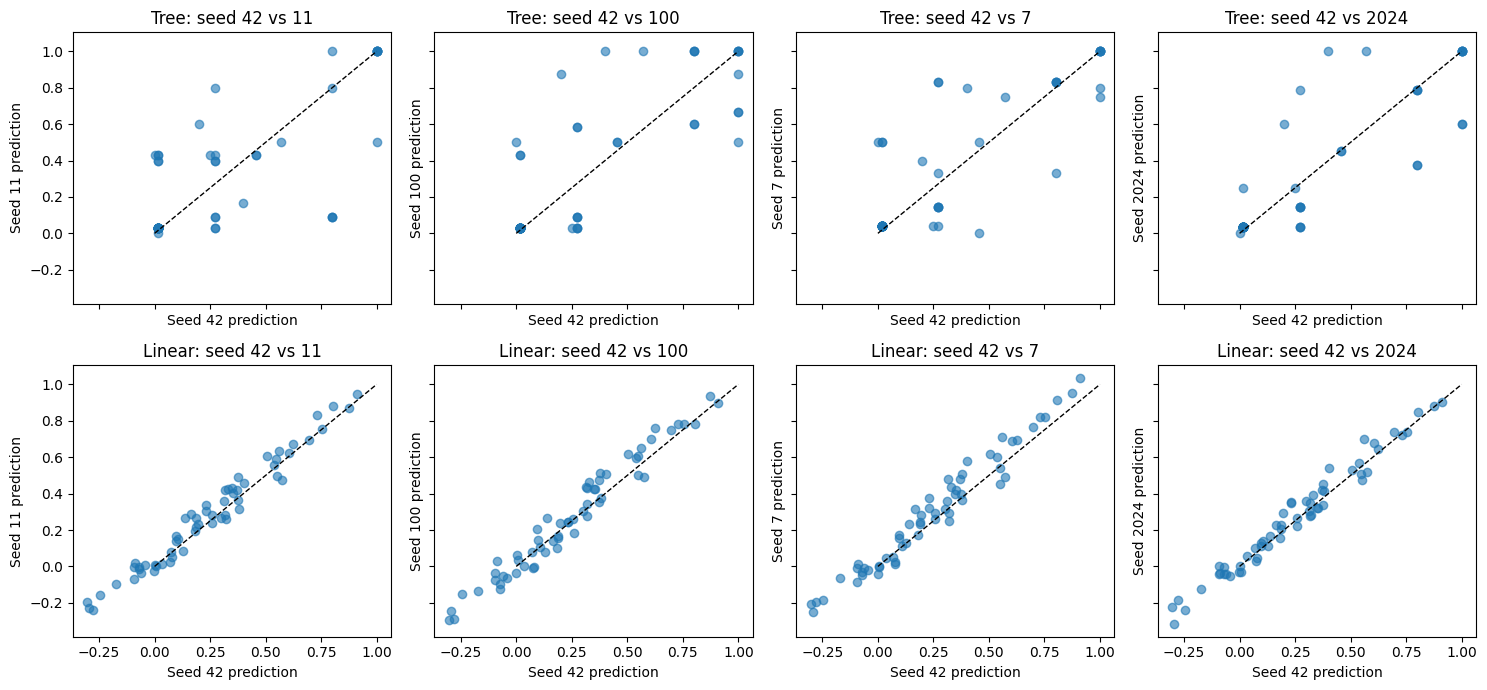

 model  seed 42 vs  correlation  intercept  slope    R2
  Tree          11        0.778      0.076  0.741 0.605
  Tree         100        0.832      0.067  0.858 0.693
  Tree           7        0.861      0.069  0.868 0.741
  Tree        2024        0.876      0.034  0.867 0.768
Linear          11        0.984      0.043  0.970 0.968
Linear         100        0.980      0.019  1.033 0.961
Linear           7        0.980      0.043  1.031 0.961
Linear        2024        0.986      0.027  0.980 0.972

Averages:
         correlation  intercept  slope     R2
model                                       
Linear        0.982      0.033  1.003  0.966
Tree          0.837      0.062  0.834  0.702


In [3]:
#Q4
X_base_te = splits[BASE][1]   # every model predicts on the seed-42 test set
tree_pred = {s: trees[s].predict_proba(X_base_te)[:, 1] for s in SEEDS}
lin_pred = {s: lins[s].predict(X_base_te) for s in SEEDS}

# 4a: scatterplots (dashed line = identical predictions)
fig, axes = plt.subplots(2, len(SEEDS) - 1, figsize=(15, 7), sharex=True, sharey=True)
for row, (p, name) in enumerate([(tree_pred, 'Tree'), (lin_pred, 'Linear')]):
    for col, s in enumerate(SEEDS[1:]):
        ax = axes[row, col]
        ax.scatter(p[BASE], p[s], alpha=0.6)
        ax.plot([0, 1], [0, 1], 'k--', lw=1)
        ax.set_title(f'{name}: seed 42 vs {s}')
        ax.set_xlabel('Seed 42 prediction'); ax.set_ylabel(f'Seed {s} prediction')
plt.tight_layout(); plt.show()

# 4b: correlation, 4c: regression of alternative predictions on seed-42 predictions
out = []
for label, pred in [('Tree', tree_pred), ('Linear', lin_pred)]:
    for s in SEEDS[1:]:
        reg = LinearRegression().fit(pred[BASE].reshape(-1, 1), pred[s])
        out.append({'model': label, 'seed 42 vs': s,
                    'correlation': np.corrcoef(pred[BASE], pred[s])[0, 1],
                    'intercept': reg.intercept_, 'slope': reg.coef_[0],
                    'R2': reg.score(pred[BASE].reshape(-1, 1), pred[s])})
res = pd.DataFrame(out).round(3)
print(res.to_string(index=False))
print('\nAverages:\n', res.groupby('model')[['correlation', 'intercept', 'slope', 'R2']].mean().round(3))

Q4 Written

**4a.** The linear-model points lie tightly along the y = x line, so those predictions are nearly identical across seeds. The tree points follow the same upward diagonal but are more spread out and form horizontal and vertical bands, because each tree's predictions come from only about 12 to 14 leaf proportions. **4b.** The linear models' correlations with the seed-42 model are about 0.98 for all four alternative seeds. The trees' correlations are lower but still fairly high, ranging from 0.78 to 0.88 (average about 0.84). **4c.** For the linear models, the intercepts are close to 0 (0.02 to 0.04), the slopes are close to 1 (0.97 to 1.03) and R² is about 0.96 to 0.97. For the trees, the intercepts are small (about 0.06), the slopes are somewhat below 1 (0.74 to 0.87) and R² is lower (0.61 to 0.77, average about 0.70). So the trees' predictions are reasonably similar across splits, but less so than the linear models'.

Q5 Explanation

**Linear models:** Yes. The standardized coefficients of the important predictors (time, ejection_fraction, serum_creatinine, age) keep the same sign and similar size across all five splits, and the predictions are nearly identical (correlation about 0.98, slope about 1, R² about 0.97). Only the weak predictors (e.g., smoking, sex, diabetes, serum_sodium) have coefficients that are near 0 and change sign across splits. **Trees:** Partly. The tree structure changes: the root split on time moves between 67.5 and 73.5, the third most important feature changes from seed to seed, and the trees have between 12 and 14 leaves. The predictions are moderately similar (correlation about 0.84, slope about 0.83, R² about 0.70) but clearly less similar than the linear models' predictions.

Q6 Explanation

**True for this dataset, with a caveat.** The trees do look noticeably different across splits (the root threshold on time moves between 67.5 and 73.5, the third most important feature changes, and the number of leaves varies), yet their predictions are fairly similar: correlations of 0.78 to 0.88, slopes of 0.74 to 0.87 and R² of 0.61 to 0.77 relative to the seed-42 tree. Many of the trees' splits are on the same strong signals (time and serum_creatinine are in every tree's top three features), so different-looking trees still rank most patients' risk in a similar way. The caveat is that the similarity depends on how the tree is built and on what we compare. A fully grown tree that outputs hard 0/1 labels (our Phase 1 setup) had much lower agreement (average correlation about 0.44, R² about 0.19), and the depth-limited trees are still clearly less stable than the linear models (correlation about 0.98, R² about 0.97). So on this dataset, different-looking models often give similar predictions, but trees give less similar predictions than linear models, and very flexible trees give much less similar ones.

### *Reflection on AI assistance
In your own words without generative AI.

AI helped us improve our Phase 1 solution. It showed that our cleaning was incomplete, that three seeds earned only partial credit, and that we had reported accuracy differences as if they were coefficient differences. The revised solution uses five stored seeds, compares the real tree structure and standardized linear coefficients, and puts all prediction comparisons in one plot grid and table. The biggest improvement was changing Q6: our Phase 1 tree gave only 0/1 predictions, which made trees look much less stable than they are.

The AI also had limitations. It first wrote its explanations after testing the code only on synthetic data, so some of its descriptions of the results were assumptions, and a few were wrong until it ran everything on our real dataset. It also chose the tree settings (max_depth=4, min_samples_leaf=5) without telling us how much the answer depends on them.

We verified the final solution by running it on the actual dataset, comparing the new results to our Phase 1 numbers, and checking that every written claim matched the output. We also checked other tree settings and retrained all models on the same training rows to rule out test-set leakage.

Remaining concerns: the dataset has only 299 rows and we used just five seeds. The tree results still depend on how the tree is built, and time would not be known when a patient is admitted.